In [1]:
import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import pvlib
import os
import warnings
warnings.filterwarnings('ignore')

try:
    pd.options.future.infer_string = False
except Exception:
    pass

font_path = os.path.expanduser('~/Library/Fonts/Cambria.ttc')
fm.fontManager.addfont(font_path)
plt.rcParams['font.family']      = 'Cambria'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'
plt.rcParams['font.size']        = 11

import platform
if platform.system() == 'Windows':
    base = r"C:\Users\sosoq\Documents\GitHub\EdenCampus-PhD\EdenCampus_PhD"
else:
    base = os.path.expanduser("~/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD")
for folder in ["01_data/weather", "01_data/demand",
               "04_results/figures", "04_results/tables"]:
    os.makedirs(os.path.join(base, folder), exist_ok=True)

# ── SHARED TIME STRUCTURE ──
def make_time_index(year):
    winter = pd.date_range(f'{year}-01-09', periods=168, freq='h')
    spring = pd.date_range(f'{year}-04-10', periods=168, freq='h')
    summer = pd.date_range(f'{year}-07-10', periods=168, freq='h')
    autumn = pd.date_range(f'{year}-10-09', periods=168, freq='h')
    return winter.append(spring).append(summer).append(autumn)

def get_pv_profile(year, time_index):
    # Load from committed weather CSV (no live PVGIS) via data_prep
    from data_prep import load_pv_profile_for_year
    return load_pv_profile_for_year(base, year, time_index)

def make_demand(time_index):
    # Use the committed authoritative demand CSV, reindexed onto time_index.
    # (Weather years vary; demand shape is held fixed to the 2023 series.)
    from data_prep import load_inputs
    base_elec = load_inputs(base, representative_weeks=False, verbose=False)["elec_demand"]
    # map by month-day-hour so any year's index picks up matching demand hours
    key = pd.Series(base_elec.values,
                    index=base_elec.index.strftime('%m-%d %H'))
    key = key[~key.index.duplicated(keep='first')]
    vals = [key.get(ts.strftime('%m-%d %H'), base_elec.mean()) for ts in time_index]
    return pd.Series(vals, index=time_index)

def run_s1_scenario(pv_profile, elec_demand, grid_price=280):
    n = pypsa.Network()
    n.set_snapshots(pv_profile.index)
    n.add("Carrier", "AC", co2_emissions=0.233)
    n.add("Bus", "Electricity Bus", carrier="AC")
    n.add("Generator", "Solar PV",
          bus="Electricity Bus", p_nom=1000,
          p_max_pu=pv_profile, marginal_cost=0)
    n.add("Generator", "Grid Import",
          bus="Electricity Bus", p_nom=2000,
          marginal_cost=grid_price/1000.0)  # £/MWh sweep -> £/kWh
    n.add("Generator", "Grid Export",
          bus="Electricity Bus", p_nom=500,
          p_max_pu=0, p_min_pu=-1, marginal_cost=-0.050)  # £/kWh
    n.add("StorageUnit", "BESS",
          bus="Electricity Bus", p_nom=500, max_hours=4,
          efficiency_store=0.95, efficiency_dispatch=0.95,
          standing_loss=0.0002, cyclic_state_of_charge=True)
    n.add("Load", "Electrical Demand",
          bus="Electricity Bus", p_set=elec_demand)
    n.optimize(solver_name='highs')
    pv_gen      = n.generators_t.p["Solar PV"]
    grid_import = n.generators_t.p["Grid Import"]
    grid_export = n.generators_t.p["Grid Export"].abs()
    pv_consumed = pv_gen.sum() - grid_export.sum()
    return {
        'PV Generation (MWh)':  round(pv_gen.sum()    / 1000, 1),
        'Grid Import (MWh)':    round(grid_import.sum()/ 1000, 1),
        'Solar Fraction (%)':   round(pv_consumed / elec_demand.sum() * 100, 1),
        'CO2 Saved (tonnes)':   round(pv_consumed * 0.233 / 1000, 1),
        'Total Cost (£k)':      round(n.objective / 1000, 1),
        'Peak Import (kW)':     round(grid_import.max(), 1),
    }

# ── RUN WEATHER SENSITIVITY ──
print("WEATHER YEAR SENSITIVITY — S1: PV + BESS")
print("=" * 55)

weather_results = []
for year in [2020, 2021, 2022, 2023]:
    ti  = make_time_index(year)
    pv  = get_pv_profile(year, ti)
    dem = make_demand(ti)
    r   = run_s1_scenario(pv, dem)
    r['Year'] = str(year)
    weather_results.append(r)
    print(f"  {year}: PV={r['PV Generation (MWh)']} MWh | "
          f"Solar={r['Solar Fraction (%)']:.1f}% | "
          f"CO2={r['CO2 Saved (tonnes)']} t")

weather_df = pd.DataFrame(weather_results).set_index('Year')
print("\n" + weather_df.to_string())
print("\nWeather sensitivity complete!")

WEATHER YEAR SENSITIVITY — S1: PV + BESS


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io: Writing time: 0.11s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.19e+04
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


...

INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io: Writing time: 0.04s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.03e+04
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-5qkve02z has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e-02, 3e-01]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1303 rows, 3581 cols, 5515 nonzeros  0s
Dependent equations search running on 1303 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1303 rows, 3581 cols, 5515 nonzeros  0s
Presolve reductions: rows 1303(-8105); columns 3581(-451); nonzeros 5515(-8597) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1846     3.0341451800e+04 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-5qkve02z
Model status        : Optimal
Simplex   iterations: 1

In [2]:
print("GRID PRICE SENSITIVITY — S1: PV + BESS")
print("=" * 55)

# Use 2023 as base year
ti_2023  = make_time_index(2023)
pv_2023  = get_pv_profile(2023, ti_2023)
dem_2023 = make_demand(ti_2023)

grid_prices   = [180, 220, 260, 280, 300, 340, 380]
price_results = []

for price in grid_prices:
    r = run_s1_scenario(pv_2023, dem_2023, grid_price=price)
    r['Grid Price (£/MWh)'] = price
    price_results.append(r)
    print(f"  £{price}/MWh: Solar={r['Solar Fraction (%)']:.1f}% | "
          f"Cost=£{r['Total Cost (£k)']:.0f}k | "
          f"Import={r['Grid Import (MWh)']} MWh")

price_df = pd.DataFrame(price_results).set_index('Grid Price (£/MWh)')
print("\n" + price_df.to_string())
print("\nGrid price sensitivity complete!")

GRID PRICE SENSITIVITY — S1: PV + BESS


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io: Writing time: 0.07s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 1.95e+04
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


...

INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io: Writing time: 0.02s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 4.12e+04
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-snbd3bwq has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e-02, 4e-01]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 2e+03]
Presolving model
1303 rows, 3581 cols, 5515 nonzeros  0s
Dependent equations search running on 1303 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1303 rows, 3581 cols, 5515 nonzeros  0s
Presolve reductions: rows 1303(-8105); columns 3581(-451); nonzeros 5515(-8597) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Ph1: 0(0) 0.0s
       1846     4.1177684586e+04 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-snbd3bwq
Model status        : Optimal
Simplex   iterations: 1

In [3]:
print("BESS SIZING SENSITIVITY — S1: PV + BESS")
print("=" * 55)

def run_bess_sizing(pv_profile, elec_demand, bess_kw, max_hours):
    n = pypsa.Network()
    n.set_snapshots(pv_profile.index)
    n.add("Carrier", "AC", co2_emissions=0.233)
    n.add("Bus", "Electricity Bus", carrier="AC")
    n.add("Generator", "Solar PV",
          bus="Electricity Bus", p_nom=1000,
          p_max_pu=pv_profile, marginal_cost=0)
    n.add("Generator", "Grid Import",
          bus="Electricity Bus", p_nom=2000,
          marginal_cost=0.280)  # £/kWh
    n.add("Generator", "Grid Export",
          bus="Electricity Bus", p_nom=500,
          p_max_pu=0, p_min_pu=-1, marginal_cost=-0.050)  # £/kWh
    n.add("StorageUnit", "BESS",
          bus="Electricity Bus",
          p_nom=bess_kw, max_hours=max_hours,
          efficiency_store=0.95, efficiency_dispatch=0.95,
          standing_loss=0.0002, cyclic_state_of_charge=True)
    n.add("Load", "Electrical Demand",
          bus="Electricity Bus", p_set=elec_demand)
    n.optimize(solver_name='highs')
    pv_gen      = n.generators_t.p["Solar PV"]
    grid_import = n.generators_t.p["Grid Import"]
    grid_export = n.generators_t.p["Grid Export"].abs()
    pv_consumed = pv_gen.sum() - grid_export.sum()
    return {
        'BESS Power (kW)':      bess_kw,
        'BESS Energy (kWh)':    bess_kw * max_hours,
        'Duration (hrs)':       max_hours,
        'Solar Fraction (%)':   round(pv_consumed / elec_demand.sum() * 100, 1),
        'CO2 Saved (tonnes)':   round(pv_consumed * 0.233 / 1000, 1),
        'Total Cost (£k)':      round(n.objective / 1000, 1),
        'Peak Import (kW)':     round(grid_import.max(), 1),
    }

sizing_configs = [
    (100, 2), (200, 2), (250, 4), (500, 2),
    (500, 4), (500, 6), (750, 4), (1000, 4),
]

sizing_results = []
for kw, hrs in sizing_configs:
    r = run_bess_sizing(pv_2023, dem_2023, kw, hrs)
    sizing_results.append(r)
    print(f"  {kw}kW / {kw*hrs}kWh ({hrs}hr): "
          f"Solar={r['Solar Fraction (%)']:.1f}% | "
          f"Cost=£{r['Total Cost (£k)']:.0f}k | "
          f"Peak={r['Peak Import (kW)']:.0f} kW")

sizing_df = pd.DataFrame(sizing_results)
print("\n" + sizing_df.to_string(index=False))
print("\nBESS sizing sensitivity complete!")

BESS SIZING SENSITIVITY — S1: PV + BESS


INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io: Writing time: 0.02s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 3.34e+04
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


...

INFO:linopy.model: Solve problem using Highs solver


INFO:linopy.io: Writing time: 0.02s


INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 4032 primals, 9408 duals
Objective: 2.93e+04
Solver model: available
Solver message: Optimal



INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, StorageUnit-fix-p_dispatch-lower, StorageUnit-fix-p_dispatch-upper, StorageUnit-fix-p_store-lower, StorageUnit-fix-p_store-upper, StorageUnit-fix-state_of_charge-lower, StorageUnit-fix-state_of_charge-upper, StorageUnit-energy_balance were not assigned to the network.


Running HiGHS 1.13.1 (git hash: 1d267d9): Copyright (c) 2026 under MIT licence terms
LP linopy-problem-bv40xpw9 has 9408 rows; 4032 cols; 14112 nonzeros
Coefficient ranges:
  Matrix  [9e-01, 1e+00]
  Cost    [5e-02, 3e-01]
  Bound   [0e+00, 0e+00]
  RHS     [1e+00, 4e+03]
Presolving model
1344 rows, 3690 cols, 5706 nonzeros  0s
Dependent equations search running on 1344 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
1344 rows, 3690 cols, 5706 nonzeros  0s
Presolve reductions: rows 1344(-8064); columns 3690(-342); nonzeros 5706(-8406) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 672(185172) 0.0s
       1951     2.9283885704e+04 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy-problem-bv40xpw9
Model status        : Optimal
Simplex   iterati

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


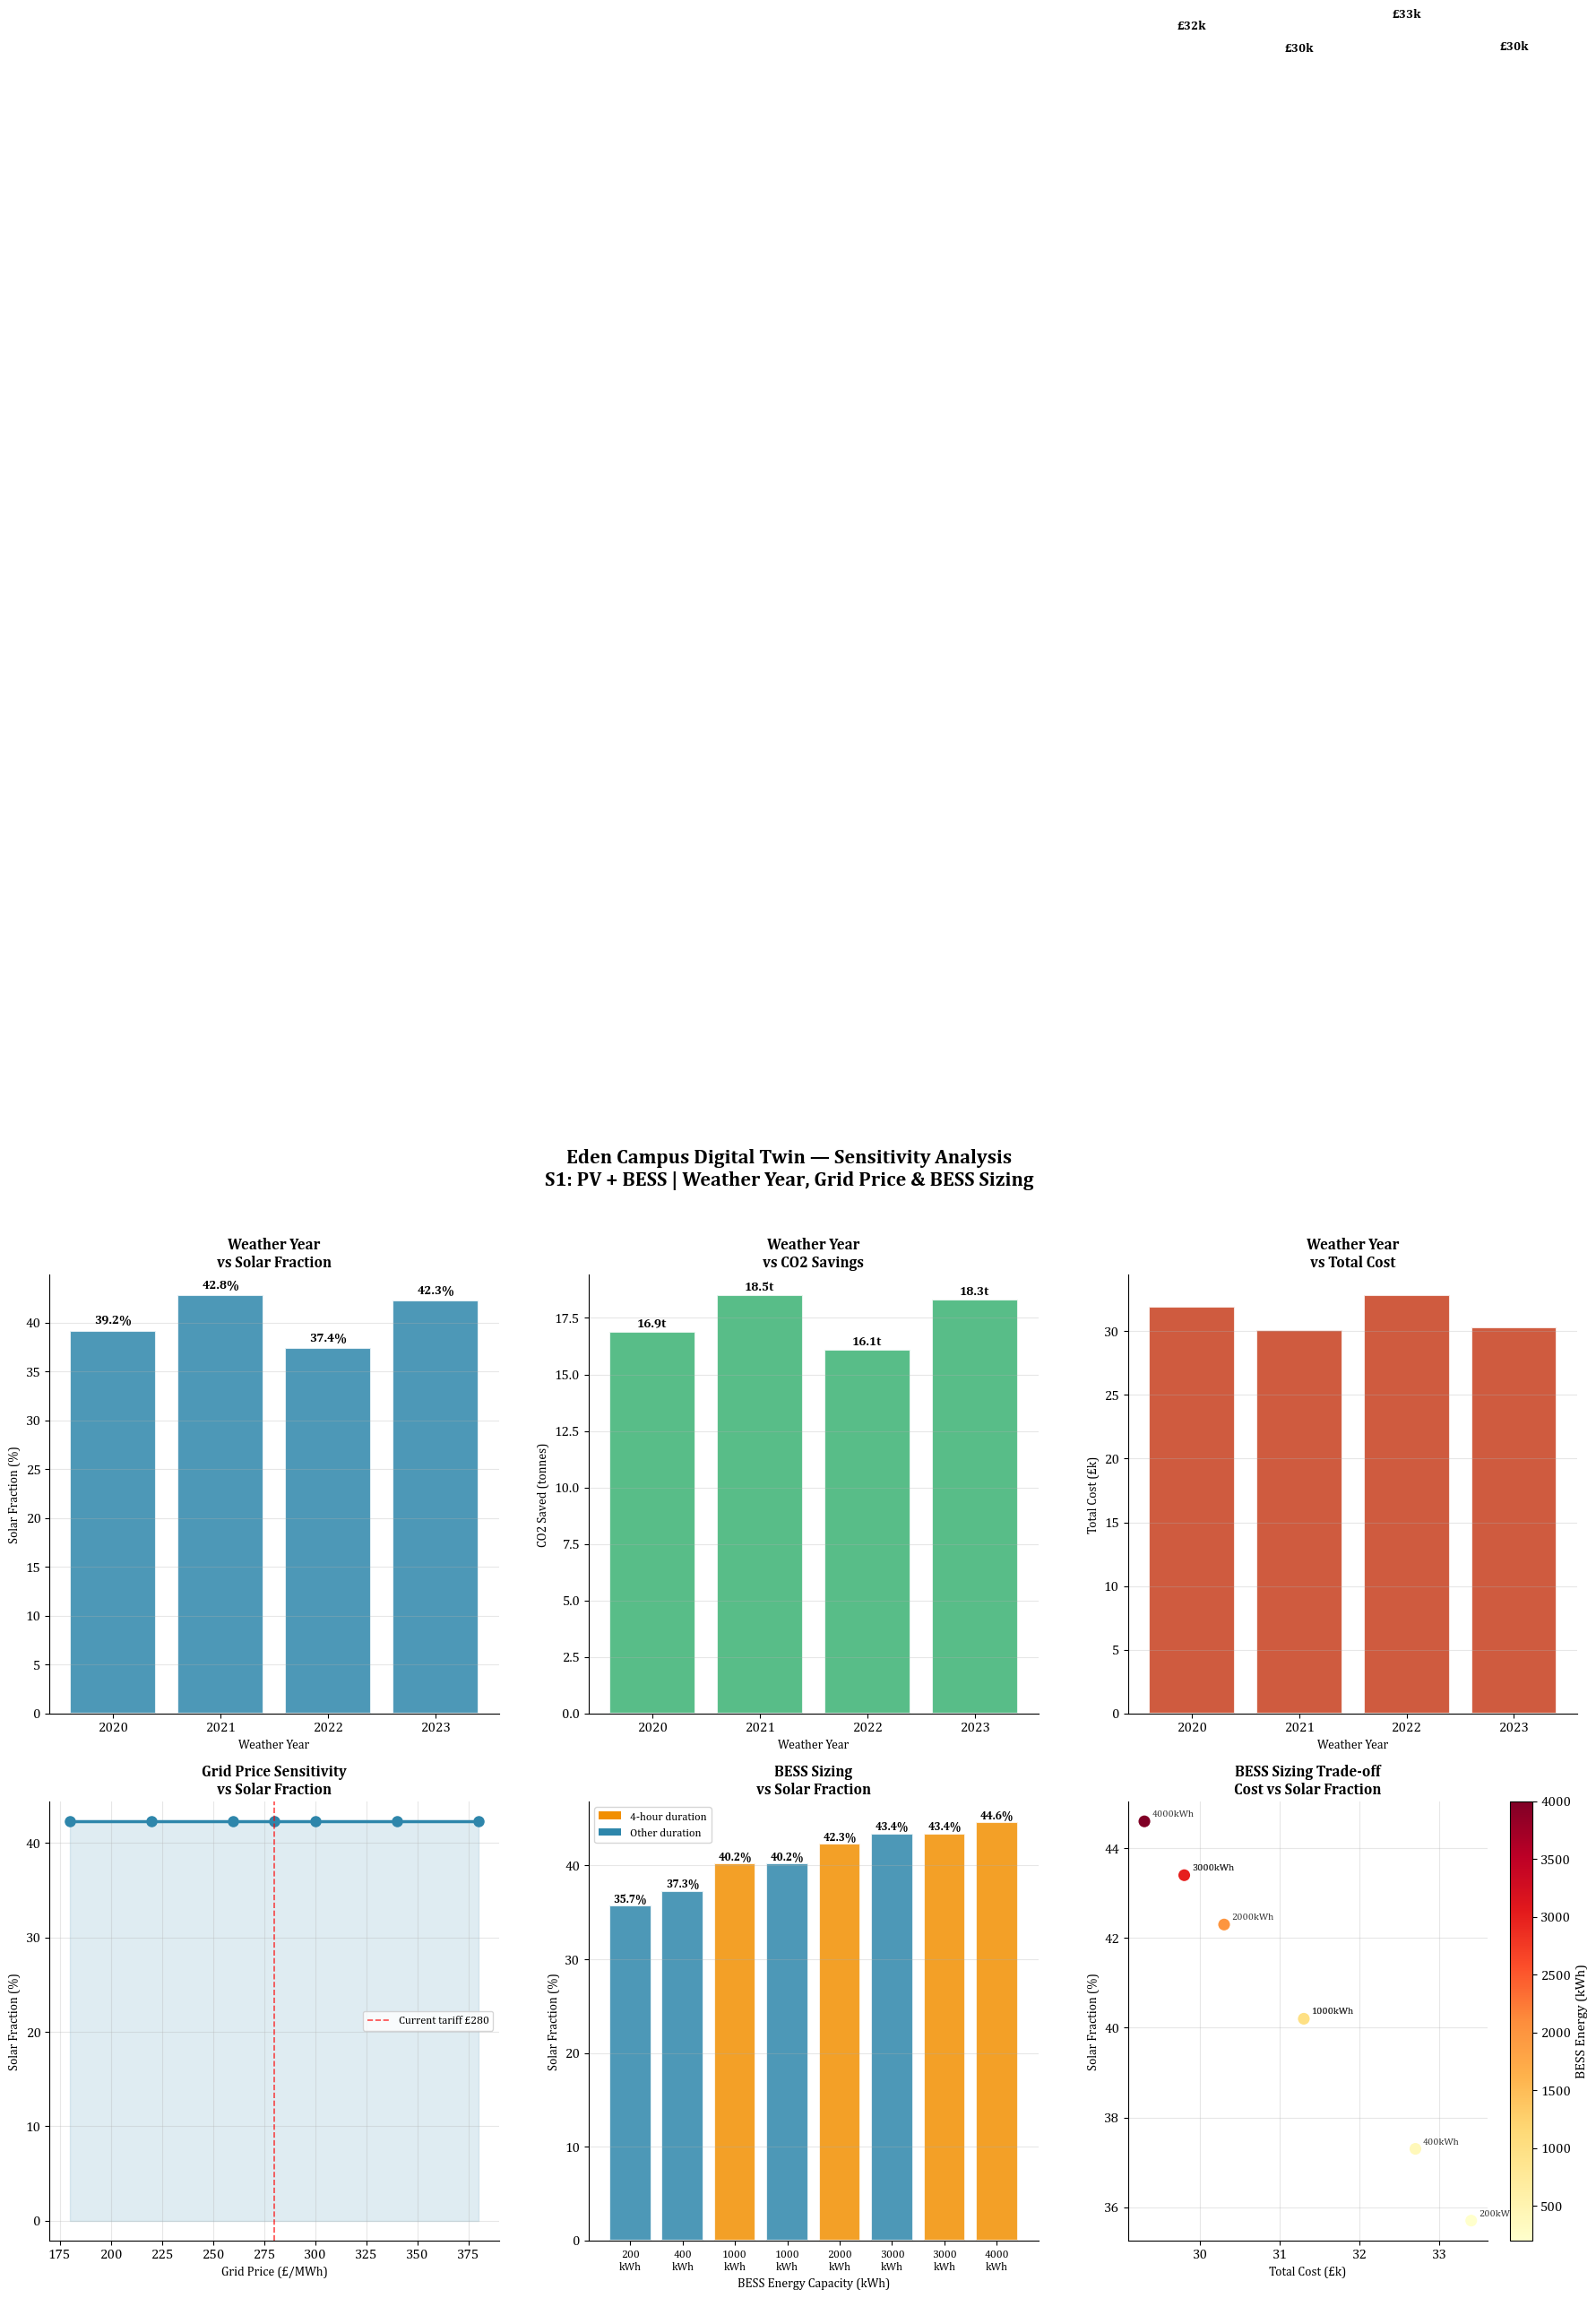

Sensitivity analysis chart saved!


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(22, 14))
fig.suptitle(
    'Eden Campus Digital Twin — Sensitivity Analysis\n'
    'S1: PV + BESS | Weather Year, Grid Price & BESS Sizing',
    fontsize=16, fontweight='bold')

# ── WEATHER: Solar Fraction ──
ax = axes[0, 0]
years  = weather_df.index.tolist()
values = weather_df['Solar Fraction (%)'].values
bars   = ax.bar(years, values, color='#2E86AB',
                alpha=0.85, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.5,
            f'{val:.1f}%', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_title('Weather Year\nvs Solar Fraction', fontsize=12, fontweight='bold')
ax.set_ylabel('Solar Fraction (%)', fontsize=10)
ax.set_xlabel('Weather Year', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── WEATHER: CO2 Saved ──
ax = axes[0, 1]
values = weather_df['CO2 Saved (tonnes)'].values
bars   = ax.bar(years, values, color='#3BB273',
                alpha=0.85, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.1,
            f'{val:.1f}t', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_title('Weather Year\nvs CO2 Savings', fontsize=12, fontweight='bold')
ax.set_ylabel('CO2 Saved (tonnes)', fontsize=10)
ax.set_xlabel('Weather Year', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── WEATHER: Total Cost ──
ax = axes[0, 2]
values = weather_df['Total Cost (£k)'].values
bars   = ax.bar(years, values, color='#C73E1D',
                alpha=0.85, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 100,
            f'£{val:.0f}k', ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_title('Weather Year\nvs Total Cost', fontsize=12, fontweight='bold')
ax.set_ylabel('Total Cost (£k)', fontsize=10)
ax.set_xlabel('Weather Year', fontsize=10)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── PRICE: Solar Fraction ──
ax = axes[1, 0]
prices = price_df.index.tolist()
values = price_df['Solar Fraction (%)'].values
ax.plot(prices, values, color='#2E86AB', linewidth=2.5,
        marker='o', markersize=8)
ax.fill_between(prices, values, alpha=0.15, color='#2E86AB')
ax.axvline(280, color='red', linewidth=1.2,
           linestyle='--', alpha=0.7, label='Current tariff £280')
ax.set_title('Grid Price Sensitivity\nvs Solar Fraction',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Solar Fraction (%)', fontsize=10)
ax.set_xlabel('Grid Price (£/MWh)', fontsize=10)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── BESS: Solar Fraction by Energy ──
ax = axes[1, 1]
energies = sizing_df['BESS Energy (kWh)'].values
values   = sizing_df['Solar Fraction (%)'].values
colors_s = ['#F18F01' if h == 4 else '#2E86AB'
            for h in sizing_df['Duration (hrs)'].values]
bars     = ax.bar(range(len(energies)), values,
                  color=colors_s, alpha=0.85,
                  edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.2,
            f'{val:.1f}%', ha='center', va='bottom',
            fontsize=9, fontweight='bold')
ax.set_xticks(range(len(energies)))
ax.set_xticklabels([f'{e:.0f}\nkWh' for e in energies], fontsize=9)
ax.set_title('BESS Sizing\nvs Solar Fraction',
             fontsize=12, fontweight='bold')
ax.set_ylabel('Solar Fraction (%)', fontsize=10)
ax.set_xlabel('BESS Energy Capacity (kWh)', fontsize=10)
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor='#F18F01', label='4-hour duration'),
    Patch(facecolor='#2E86AB', label='Other duration'),
], fontsize=9)
ax.grid(True, alpha=0.3, axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# ── BESS: Cost vs Solar Trade-off ──
ax = axes[1, 2]
costs  = sizing_df['Total Cost (£k)'].values
solar  = sizing_df['Solar Fraction (%)'].values
sizes  = sizing_df['BESS Energy (kWh)'].values
sc     = ax.scatter(costs, solar, c=sizes,
                    cmap='YlOrRd', s=120, zorder=3,
                    edgecolors='white', linewidth=1.5)
for i, (c, s, e) in enumerate(zip(costs, solar, sizes)):
    ax.annotate(f'{e:.0f}kWh',
                (c, s), textcoords='offset points',
                xytext=(6, 4), fontsize=8, color='#333333')
plt.colorbar(sc, ax=ax, label='BESS Energy (kWh)')
ax.set_title('BESS Sizing Trade-off\nCost vs Solar Fraction',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Total Cost (£k)', fontsize=10)
ax.set_ylabel('Solar Fraction (%)', fontsize=10)
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
save_path = os.path.join(base, "04_results/figures",
                          "sensitivity_analysis.png")
plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()
print("Sensitivity analysis chart saved!")

In [5]:
os.makedirs(os.path.join(base, "04_results/tables"), exist_ok=True)

# ── Save Excel ──
excel_path = os.path.join(base, "04_results/tables",
                           "sensitivity_analysis.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    weather_df.to_excel(writer, sheet_name='Weather Year')
    price_df.to_excel(writer,   sheet_name='Grid Price')
    sizing_df.to_excel(writer,  sheet_name='BESS Sizing',  index=False)
print(f"Excel saved: {excel_path}")

# ── Print LaTeX tables ──
print("\n── Weather Year LaTeX Table ──\n")
print(weather_df.to_latex(
    caption='Weather year sensitivity analysis for S1 (PV + BESS).',
    label='tab:sensitivity_weather',
    float_format='{:.1f}'.format))

print("\n── Grid Price LaTeX Table ──\n")
print(price_df[['Solar Fraction (%)',
                 'CO2 Saved (tonnes)',
                 'Total Cost (£k)']].to_latex(
    caption='Grid electricity price sensitivity analysis for S1 (PV + BESS).',
    label='tab:sensitivity_price',
    float_format='{:.1f}'.format))

print("\n── BESS Sizing LaTeX Table ──\n")
print(sizing_df.to_latex(
    index=False,
    caption='BESS capacity sizing sensitivity analysis for S1 (PV + BESS).',
    label='tab:sensitivity_bess',
    float_format='{:.1f}'.format))

print("\nAll sensitivity tables saved!")

Excel saved: /Users/everythingkrypto/Documents/GitHub/EdenCampus-PhD/EdenCampus_PhD/04_results/tables/sensitivity_analysis.xlsx

── Weather Year LaTeX Table ──

\begin{table}
\caption{Weather year sensitivity analysis for S1 (PV + BESS).}
\label{tab:sensitivity_weather}
\begin{tabular}{lrrrrrr}
\toprule
 & PV Generation (MWh) & Grid Import (MWh) & Solar Fraction (%) & CO2 Saved (tonnes) & Total Cost (£k) & Peak Import (kW) \\
Year &  &  &  &  &  &  \\
\midrule
2020 & 72.6 & 113.8 & 39.2 & 16.9 & 31.9 & 652.1 \\
2021 & 79.2 & 107.5 & 42.8 & 18.5 & 30.1 & 644.8 \\
2022 & 69.2 & 117.2 & 37.4 & 16.1 & 32.8 & 667.8 \\
2023 & 78.3 & 108.4 & 42.3 & 18.3 & 30.3 & 652.7 \\
\bottomrule
\end{tabular}
\end{table}


── Grid Price LaTeX Table ──

\begin{table}
\caption{Grid electricity price sensitivity analysis for S1 (PV + BESS).}
\label{tab:sensitivity_price}
\begin{tabular}{lrrr}
\toprule
 & Solar Fraction (%) & CO2 Saved (tonnes) & Total Cost (£k) \\
Grid Price (£/MWh) &  &  &  \\
\midrule
180 